# Evidence-grounded fine-grained image difference: real-data execution

This notebook executes the existing alignment-aware pipeline on two real annotated test-split
slices. It saves numeric tables and every visual artifact to `outputs/real_dataset_evaluation/`.
All pixel metrics are computed against the supplied masks at the native A-image resolution.

This is a reproducible CPU execution, not a benchmark-superiority claim. No labels are used to
tune alignment, thresholds, or the evidence policy.


## 1. Data provenance, licences, and scope

| Dataset | Annotation / official access | What is used in this execution |
|---|---|---|
| [LEVIR-CD](https://justchenhao.github.io/LEVIR/) | 637 VHR Google Earth pairs with expert-checked binary building-change masks. The official page links Google Drive/Baidu Drive and restricts use to academic, non-commercial use subject to Google Earth terms. | Fixed test rows from public `ericyu/LEVIRCD_Cropped_256` Parquet **mirror**. It is not represented as an official redistribution; source ID/split/rows/timestamp are written beside data. |
| [SYSU-CD](https://github.com/liumency/SYSU-CD) | Paired 256×256 land-cover change images and binary masks; the official repository is the access authority. | Fixed test rows from public `ericyu/SYSU_CD` Parquet **mirror**. Obtain the official data and comply with current terms before broader use. |

The helper requests only the stated test rows from Hugging Face's dataset-server API, checks each
download is readable, and writes `provenance.json`. It never silently substitutes synthetic data.
The compact fixed slice is an execution check, not the full official benchmark protocol.

**Actually executed stages:** validation → ORB/RANSAC alignment → photometrically robust Lab,
SSIM and edge residuals → native crop re-inspection → flow/illumination/compression/blur nuisance
checks → independent-family evidence reconciliation → accepted/review/abstained claims.
LightGlue/LoFTR, OCR, AnyChange, M³Diff and VLM remain optional and are not claimed as run here.


In [1]:
from pathlib import Path
import json, os, platform, sys, time
import cv2, matplotlib.pyplot as plt, numpy as np, pandas as pd, torch

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
RUN_ROOT = ROOT / "outputs" / "real_dataset_evaluation"
DATA_ROOT = ROOT / "data" / "real_eval_mirror_slices"
RUN_ROOT.mkdir(parents=True, exist_ok=True)
environment = {"python": sys.version, "platform": platform.platform(), "opencv": cv2.__version__,
               "torch": torch.__version__, "cuda_available": torch.cuda.is_available(), "run_root": str(RUN_ROOT)}
(RUN_ROOT / "environment.json").write_text(json.dumps(environment, indent=2))
pd.DataFrame(environment.items(), columns=["field", "value"])


,field,value
0,python,"3.13.9 | packaged by Anaconda, Inc. | (main, O..."
1,platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.39
2,opencv,5.0.0
3,torch,2.14.1+cu130
4,cuda_available,True
5,run_root,/home/vu-lab03-pc17/image_difference/outputs/r...


## 2. Fetch fixed, held-out slices

Indices were fixed before inspecting labels or predictions. Evaluation and demonstration rows are
disjoint, so cherry-picking cannot change the measured tables. A network error remains a visible
blocker; this notebook will not fall back to made-up data.


In [2]:
from idu.real_eval import fetch_hf_test_slice

EVAL_ROWS = {"ericyu/LEVIRCD_Cropped_256": [0, 7, 19, 31, 43],
             "ericyu/SYSU_CD": [0, 11, 23, 37, 53]}
DEMO_ROWS = {"ericyu/LEVIRCD_Cropped_256": [101], "ericyu/SYSU_CD": [127]}
evaluation_pairs, demo_pairs = [], []
for dataset_id, rows in EVAL_ROWS.items():
    evaluation_pairs += fetch_hf_test_slice(dataset_id, DATA_ROOT / dataset_id.replace("/", "__") / "evaluation", rows)
for dataset_id, rows in DEMO_ROWS.items():
    demo_pairs += fetch_hf_test_slice(dataset_id, DATA_ROOT / dataset_id.replace("/", "__") / "demonstrations", rows)
pd.DataFrame(evaluation_pairs + demo_pairs)[["dataset_id", "split", "row_idx", "id", "image_a", "mask"]]


,dataset_id,split,row_idx,id,image_a,mask
0,ericyu/LEVIRCD_Cropped_256,test,0,ericyu__LEVIRCD_Cropped_256_test_00000,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
1,ericyu/LEVIRCD_Cropped_256,test,7,ericyu__LEVIRCD_Cropped_256_test_00007,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
2,ericyu/LEVIRCD_Cropped_256,test,19,ericyu__LEVIRCD_Cropped_256_test_00019,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
3,ericyu/LEVIRCD_Cropped_256,test,31,ericyu__LEVIRCD_Cropped_256_test_00031,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
4,ericyu/LEVIRCD_Cropped_256,test,43,ericyu__LEVIRCD_Cropped_256_test_00043,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
5,ericyu/SYSU_CD,test,0,ericyu__SYSU_CD_test_00000,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
6,ericyu/SYSU_CD,test,11,ericyu__SYSU_CD_test_00011,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
7,ericyu/SYSU_CD,test,23,ericyu__SYSU_CD_test_00023,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
8,ericyu/SYSU_CD,test,37,ericyu__SYSU_CD_test_00037,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...
9,ericyu/SYSU_CD,test,53,ericyu__SYSU_CD_test_00053,/home/vu-lab03-pc17/image_difference/data/real...,/home/vu-lab03-pc17/image_difference/data/real...


## 3. Reproducible configuration

The installed `classical` preset exercises the repository's genuine correspondence, residual,
localization and decision policy with no hidden checkpoint download. Configuration is frozen before
the labelled slice is evaluated and recorded in each result file.


In [3]:
from idu import Pipeline, make_config
CFG = make_config("classical", device="cpu", domain="fixed_camera", output_dir=str(RUN_ROOT / "pair_artifacts"),
                  analysis_max_side=512, z_high=6.0, z_low=3.0, min_region_px=12,
                  use_registration=True, use_reinspection=True, use_flow=True,
                  use_texture_features=False, seed=0)
PIPE = Pipeline(CFG)
print(json.dumps(CFG.to_dict(), indent=2))


{
  "preset": "classical",
  "device": "cpu",
  "domain": "fixed_camera",
  "scope": "",
  "output_dir": "/home/vu-lab03-pc17/image_difference/outputs/real_dataset_evaluation/pair_artifacts",
  "seed": 0,
  "use_registration": true,
  "use_lowlevel": true,
  "use_ocr": false,
  "use_vlm": false,
  "use_m3diff": false,
  "use_anychange": false,
  "use_reinspection": true,
  "use_fusion": true,
  "use_abstention": true,
  "use_compat_model": false,
  "dino_model": "facebook/dinov2-small",
  "min_side_px": 64,
  "max_pixels": 40000000,
  "matcher": "orb",
  "lightglue_features": "superpoint",
  "max_keypoints": 4096,
  "allow_matcher_fallback": true,
  "ransac_thresh_px": 3.0,
  "min_inliers": 15,
  "use_flow": true,
  "analysis_max_side": 512,
  "photometric_normalize": true,
  "tolerance_px": 1,
  "ssim_sigma": 1.5,
  "z_high": 6.0,
  "z_low": 3.0,
  "pixel_only_accept_factor": 2.0,
  "degraded_factor": 1.5,
  "tiny_region_px": 64,
  "min_region_px": 12,
  "noise_floor": {
    "lab": 2.

## 4. Baseline and evidence-grounded evaluation

The baseline is an unregistered RGB residual with an image-only Otsu threshold. The improved mask
unions only regions attached to `accepted` or `needs_review` claims; abstentions and semantic-only
hypotheses never count. Metrics are micro pixel precision/recall/F1/Dice/IoU/accuracy plus
pair-level changed/not-changed detection. Pixel accuracy is reported but is not treated as a
standalone quality score because unchanged pixels dominate remote-sensing masks.


In [4]:
from idu.real_eval import binary_metrics, evaluate_slice, naive_residual_baseline, read_binary_mask, summarise

baseline_rows = []
for p in evaluation_pairs:
    pred = naive_residual_baseline(p["image_a"], p["image_b"])
    baseline_rows.append({"dataset": p["dataset_id"], "id": p["id"], "row_idx": p["row_idx"],
                          **binary_metrics(pred, read_binary_mask(p["mask"], pred.shape))})
BASELINE_PER_PAIR = pd.DataFrame(baseline_rows)
baseline_summary = pd.DataFrame([{ "dataset": ds, "variant": "naive_unregistered_rgb_otsu", **summarise(x.to_dict("records"))}
                                 for ds, x in BASELINE_PER_PAIR.groupby("dataset", sort=False)])
display(baseline_summary)


,dataset,variant,pairs,tp,fp,fn,tn,precision,recall,f1,...,dice,accuracy,pair_tp,pair_fp,pair_fn,pair_tn,pair_precision,pair_recall,pair_f1,pair_accuracy
0,ericyu/LEVIRCD_Cropped_256,naive_unregistered_rgb_otsu,5,20832,38746,27192,240910,0.349659,0.433783,0.387205,...,0.387205,0.798773,3,2,0,0,0.6,1.0,0.75,0.6
1,ericyu/SYSU_CD,naive_unregistered_rgb_otsu,5,21637,25974,39751,240318,0.454454,0.352463,0.397013,...,0.397013,0.799423,5,0,0,0,1.0,1.0,1.00,1.0


In [5]:
IMPROVED_PER_PAIR, improved_summary = evaluate_slice(PIPE, evaluation_pairs, out_dir=RUN_ROOT / "improved",
                                                       decisions=("accepted", "needs_review"))
improved_summary.insert(1, "variant", "evidence_grounded_classical")
display(improved_summary)


[1/10] ericyu__LEVIRCD_Cropped_256_test_00000: F1=0.0, IoU=0.0, comparable_with_warnings


[2/10] ericyu__LEVIRCD_Cropped_256_test_00007: F1=0.0, IoU=0.0, inconclusive


[3/10] ericyu__LEVIRCD_Cropped_256_test_00019: F1=0.0, IoU=0.0, comparable_with_warnings


[4/10] ericyu__LEVIRCD_Cropped_256_test_00031: F1=None, IoU=None, comparable_with_warnings


[5/10] ericyu__LEVIRCD_Cropped_256_test_00043: F1=0.0, IoU=0.0, comparable_with_warnings


...

[7/10] ericyu__SYSU_CD_test_00011: F1=0.0, IoU=0.0, comparable_with_warnings


[8/10] ericyu__SYSU_CD_test_00023: F1=0.17849312338050627, IoU=0.09799201181813208, inconclusive


[9/10] ericyu__SYSU_CD_test_00037: F1=0.0, IoU=0.0, comparable_with_warnings


[10/10] ericyu__SYSU_CD_test_00053: F1=0.9095734224493808, IoU=0.8341445826572922, comparable_with_warnings


,pairs,variant,tp,fp,fn,tn,precision,recall,f1,iou,...,pair_fp,pair_fn,pair_tn,pair_precision,pair_recall,pair_f1,pair_accuracy,dataset,mean_latency_s,max_peak_gpu_gb
0,5,evidence_grounded_classical,0,1407,48024,278249,0.000000,0.000000,0.000000,0.000000,...,1,2,1,0.5,0.333333,0.400000,0.4,ericyu/LEVIRCD_Cropped_256,1.459780,0.0
1,5,evidence_grounded_classical,7848,1842,53540,264450,0.809907,0.127843,0.220828,0.124118,...,0,1,0,1.0,0.800000,0.888889,0.8,ericyu/SYSU_CD,1.298128,0.0


## 5. Ablation: remove registration

Only geometric registration changes in this ablation; the test slice, residual thresholds and
evidence policy remain fixed. This provides a direct, limited measurement of correspondence value
without tuning on the test labels.


In [6]:
from dataclasses import replace
NO_REG_PIPE = Pipeline(replace(CFG, use_registration=False))
NO_REG_PER_PAIR, no_reg_summary = evaluate_slice(NO_REG_PIPE, evaluation_pairs,
    out_dir=RUN_ROOT / "ablation_no_registration", decisions=("accepted", "needs_review"))
no_reg_summary.insert(1, "variant", "evidence_no_registration")
COMPARISON = pd.concat([baseline_summary, improved_summary, no_reg_summary], ignore_index=True, sort=False)
COMPARISON.to_csv(RUN_ROOT / "metrics_by_dataset.csv", index=False)
BASELINE_PER_PAIR.to_csv(RUN_ROOT / "baseline_per_pair.csv", index=False)
IMPROVED_PER_PAIR.to_csv(RUN_ROOT / "improved_per_pair.csv", index=False)
NO_REG_PER_PAIR.to_csv(RUN_ROOT / "no_registration_per_pair.csv", index=False)
display(COMPARISON[["dataset", "variant", "pairs", "precision", "recall", "f1", "iou", "dice", "accuracy", "pair_f1", "pair_accuracy", "mean_latency_s"]])


[1/10] ericyu__LEVIRCD_Cropped_256_test_00000: F1=0.0, IoU=0.0, comparable


[2/10] ericyu__LEVIRCD_Cropped_256_test_00007: F1=0.04237356275629171, IoU=0.021645377253871112, comparable


[3/10] ericyu__LEVIRCD_Cropped_256_test_00019: F1=0.14902309058614566, IoU=0.0805105076288264, comparable_with_warnings


[4/10] ericyu__LEVIRCD_Cropped_256_test_00031: F1=0.0, IoU=0.0, comparable_with_warnings


[5/10] ericyu__LEVIRCD_Cropped_256_test_00043: F1=0.07592089230480832, IoU=0.03945830085736555, comparable_with_warnings


...

[7/10] ericyu__SYSU_CD_test_00011: F1=0.14326029216467465, IoU=0.07715690657130085, comparable


[8/10] ericyu__SYSU_CD_test_00023: F1=0.24144115419871667, IoU=0.13729489620161364, comparable


[9/10] ericyu__SYSU_CD_test_00037: F1=0.030774321641297155, IoU=0.01562762560914132, comparable_with_warnings


[10/10] ericyu__SYSU_CD_test_00053: F1=0.9095734224493808, IoU=0.8341445826572922, comparable_with_warnings


,dataset,variant,pairs,precision,recall,f1,iou,dice,accuracy,pair_f1,pair_accuracy,mean_latency_s
0,ericyu/LEVIRCD_Cropped_256,naive_unregistered_rgb_otsu,5,0.349659,0.433783,0.387205,0.240083,0.387205,0.798773,0.750000,0.6,NaN
1,ericyu/SYSU_CD,naive_unregistered_rgb_otsu,5,0.454454,0.352463,0.397013,0.247671,0.397013,0.799423,1.000000,1.0,NaN
2,ericyu/LEVIRCD_Cropped_256,evidence_grounded_classical,5,0.000000,0.000000,0.000000,0.000000,0.000000,0.849149,0.400000,0.4,1.459780
3,ericyu/SYSU_CD,evidence_grounded_classical,5,0.809907,0.127843,0.220828,0.124118,0.220828,0.830988,0.888889,0.8,1.298128
4,ericyu/LEVIRCD_Cropped_256,evidence_no_registration,5,0.181485,0.045311,0.072516,0.037622,0.072516,0.830133,0.750000,0.6,1.781443
5,ericyu/SYSU_CD,evidence_no_registration,5,0.468787,0.201961,0.282302,0.164349,0.282302,0.807620,1.000000,1.0,1.469777


## 6. Two additional real-pair demonstrations

These disjoint test rows are excluded from the metric tables. Green overlay is the exact mask that
was measured. The report text is constrained by the repository's claim verifier: without a
successfully executed semantic model it will say localized visual change rather than invent an
object/action label.


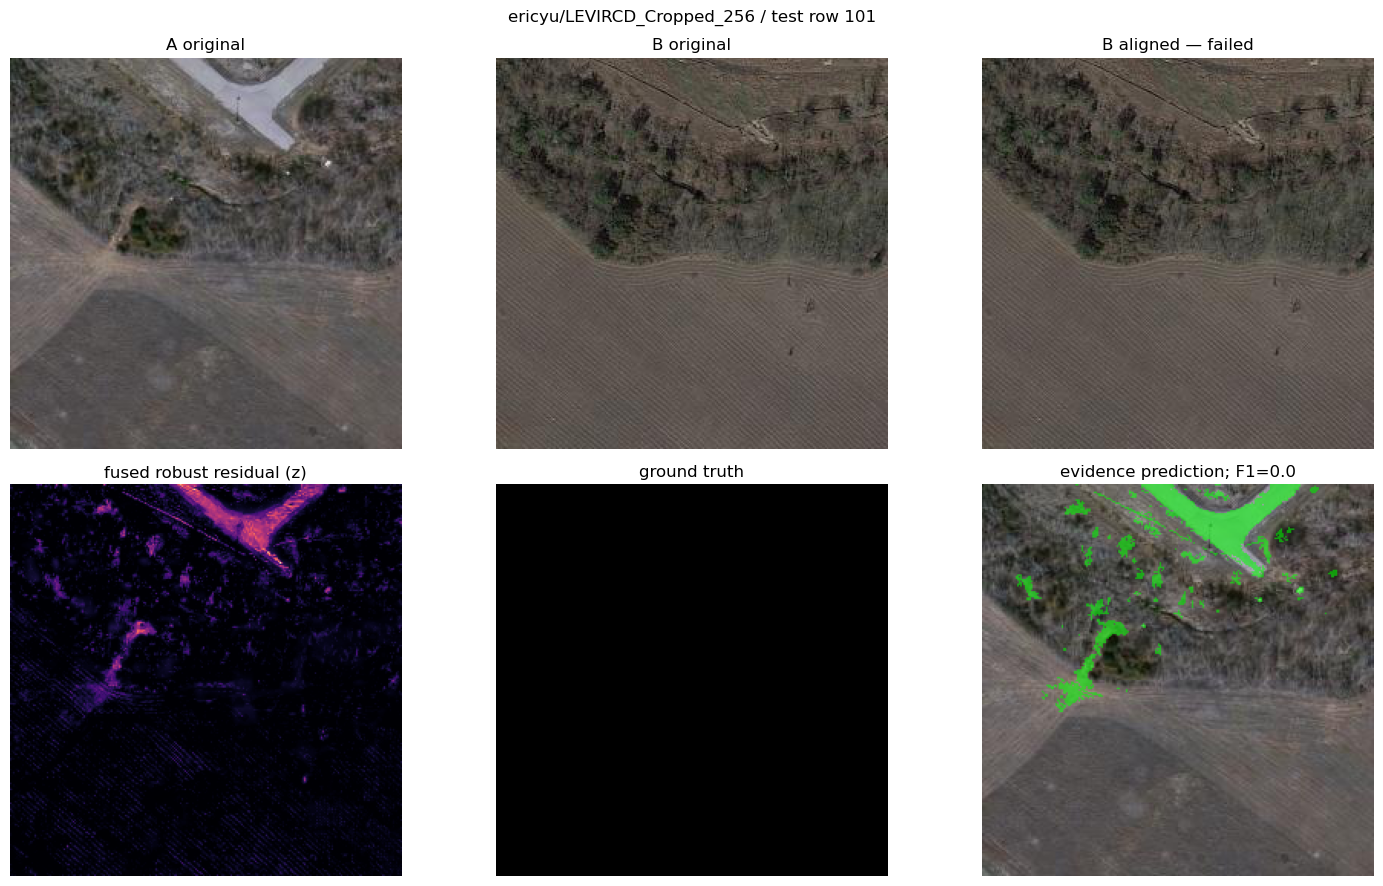

**Comparison status:** comparable_with_warnings  
**Alignment:** scale_only_assumed (failed)
**Pair warnings:** A:visible_compression_blocking  
**Components that ran:** matcher, lowlevel, matcher:orb  

### Accepted changes (0)
- none verified (this is not proof that nothing changed)

### Needs review (4)
- `claim_001` localized visual change (no semantic explanation) at A[54, 0, 232, 85]. Evidence: appearance. alignment unreliable: residual may be registration error
- `claim_002` localized visual change (no semantic explanation) at A[22, 50, 131, 149]. Evidence: appearance. alignment unreliable: residual may be registration error
- `claim_008` localized visual change (no semantic explanation) at A[172, 34, 230, 77]. Evidence: appearance. alignment unreliable: residual may be registration error
- `claim_015` localized visual change (no semantic explanation) at A[135, 30, 196, 84]. Evidence: appearance. alignment unreliable: residual may be registration error

### Plausible nuisance fa

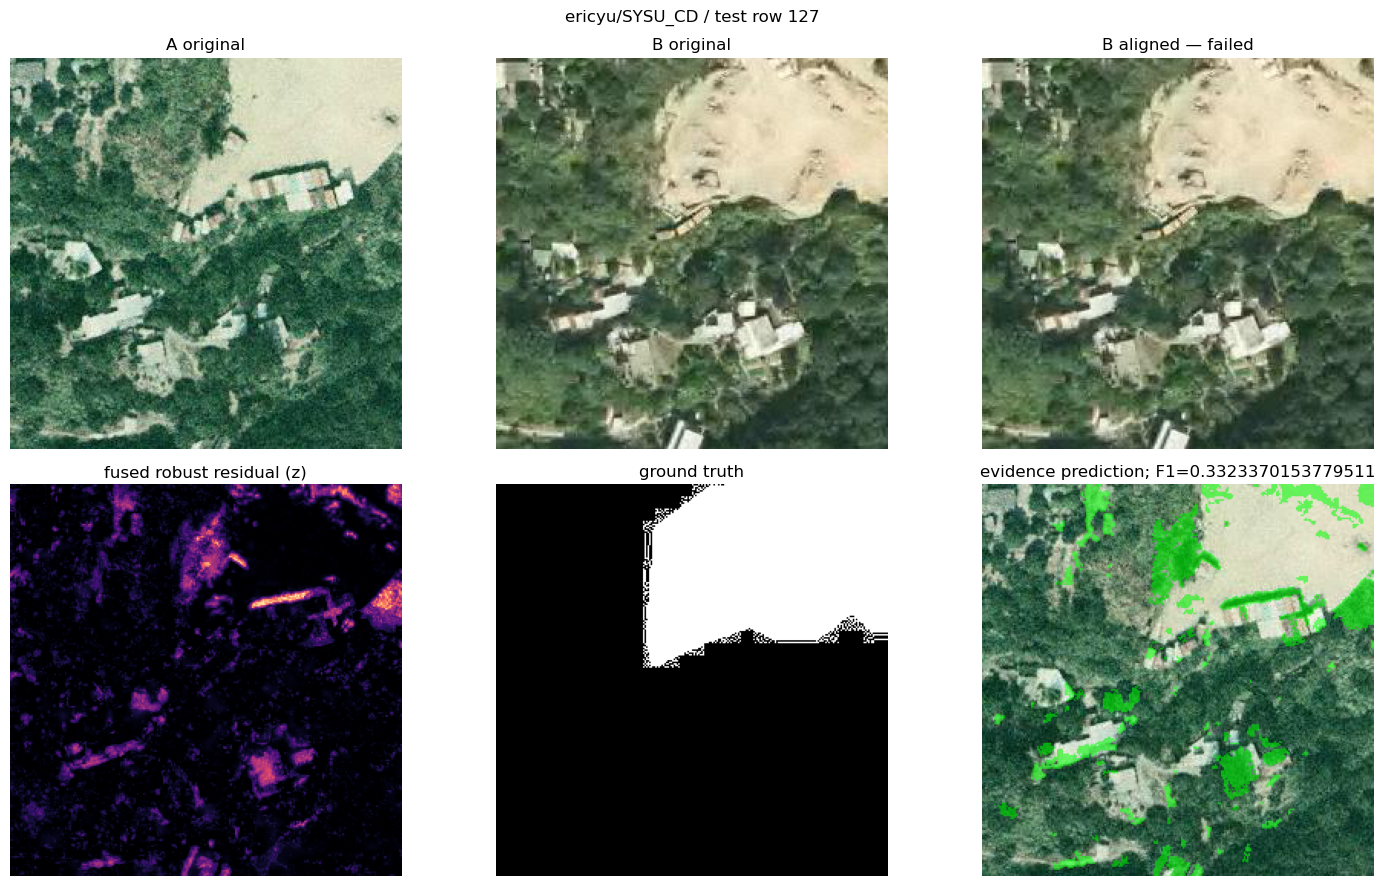

**Comparison status:** inconclusive  
**Alignment:** scale_only_assumed (failed)
**Components that ran:** matcher, lowlevel, matcher:orb  

### Accepted changes (0)
- none verified (this is not proof that nothing changed)

### Needs review (20)
- `claim_001` localized visual change (no semantic explanation) at A[131, 32, 256, 130]. Evidence: appearance. alignment unreliable: residual may be registration error
- `claim_002` localized visual change (no semantic explanation) at A[79, 0, 180, 104]. Evidence: appearance. alignment unreliable: residual may be registration error
- `claim_003` localized visual change (no semantic explanation) at A[220, 0, 256, 40]. Evidence: appearance. alignment unreliable: residual may be registration error
- `claim_004` localized visual change (no semantic explanation) at A[158, 0, 256, 44]. Evidence: appearance. alignment unreliable: residual may be registration error
- `claim_005` localized visual change (no semantic explanation) at A[108, 47, 169, 110]. 

,dataset,row_idx,precision,recall,f1,iou,comparison_status
0,ericyu/LEVIRCD_Cropped_256,101,0.000000,NaN,0.000000,0.000000,comparable_with_warnings
1,ericyu/SYSU_CD,127,0.522047,0.243757,0.332337,0.199283,inconclusive


In [7]:
from idu.real_eval import evidence_mask

def overlay(image, mask):
    out = image.copy(); out[mask] = (0.45 * out[mask] + 0.55 * np.array([0, 255, 0])).astype(np.uint8); return out

DEMO_RESULTS = []
for pair in demo_pairs:
    res, art = PIPE.run(pair["image_a"], pair["image_b"], out_dir=str(RUN_ROOT / "demonstrations" / pair["id"]), do_export=True)
    gt, pred = read_binary_mask(pair["mask"], art["img_a"].shape[:2]), evidence_mask(art)
    metric = binary_metrics(pred, gt); fused = art.get("low", {}).get("maps", {}).get("fused", np.zeros(gt.shape))
    if fused.shape != gt.shape: fused = cv2.resize(fused, (gt.shape[1], gt.shape[0]))
    panels = [(art["img_a"], "A original", None), (art["img_b"], "B original", None),
              (art["aligned_b"], f"B aligned — {res['alignment']['status']}", None),
              (fused, "fused robust residual (z)", "magma"), (gt, "ground truth", "gray"),
              (overlay(art["img_a"], pred), f"evidence prediction; F1={metric['f1']}", None)]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, (image, title, cmap) in zip(axes.flat, panels): ax.imshow(image, cmap=cmap); ax.set_title(title); ax.axis("off")
    fig.suptitle(f"{pair['dataset_id']} / test row {pair['row_idx']}"); fig.tight_layout()
    fig.savefig(RUN_ROOT / "demonstrations" / f"{pair['id']}_six_panel.png", dpi=150, bbox_inches="tight"); plt.show()
    print(res["report"]["text"])
    DEMO_RESULTS.append({"dataset": pair["dataset_id"], "row_idx": pair["row_idx"], **metric,
                         "comparison_status": res["comparison_status"], "report": res["report"]["text"]})
pd.DataFrame(DEMO_RESULTS).to_csv(RUN_ROOT / "demonstration_metrics.csv", index=False)
pd.DataFrame(DEMO_RESULTS)[["dataset", "row_idx", "precision", "recall", "f1", "iou", "comparison_status"]]


## 7. Measured summary and limitations

The values below are emitted by this run, not copied from a paper. Each pair's `result.json`
records component status, inputs, alignment quality, evidence graph, claims, timings and maps.

Limitations: ten fixed pairs are an execution slice rather than a leaderboard test; binary masks
do not support semantic-caption accuracy; no document/OCR benchmark is included; and no compatible
M³Diff/AnyChange/VLM checkpoint was installed for this CPU run. Optional failures are visible in
the component table rather than silently replaced by predictions.


In [8]:
print("Saved tables:")
for path in sorted(RUN_ROOT.glob("*.csv")): print(" -", path)
display(COMPARISON[["dataset", "variant", "pairs", "precision", "recall", "f1", "iou", "dice", "accuracy",
                    "pair_precision", "pair_recall", "pair_f1", "pair_accuracy", "mean_latency_s"]])
print("\nActual component status from the last executed pair:")
display(pd.DataFrame(res["component_status"]))
PIPE.close(); NO_REG_PIPE.close()


Saved tables:
 - /home/vu-lab03-pc17/image_difference/outputs/real_dataset_evaluation/baseline_per_pair.csv
 - /home/vu-lab03-pc17/image_difference/outputs/real_dataset_evaluation/demonstration_metrics.csv
 - /home/vu-lab03-pc17/image_difference/outputs/real_dataset_evaluation/improved_per_pair.csv
 - /home/vu-lab03-pc17/image_difference/outputs/real_dataset_evaluation/metrics_by_dataset.csv
 - /home/vu-lab03-pc17/image_difference/outputs/real_dataset_evaluation/no_registration_per_pair.csv


,dataset,variant,pairs,precision,recall,f1,iou,dice,accuracy,pair_precision,pair_recall,pair_f1,pair_accuracy,mean_latency_s
0,ericyu/LEVIRCD_Cropped_256,naive_unregistered_rgb_otsu,5,0.349659,0.433783,0.387205,0.240083,0.387205,0.798773,0.6,1.000000,0.750000,0.6,NaN
1,ericyu/SYSU_CD,naive_unregistered_rgb_otsu,5,0.454454,0.352463,0.397013,0.247671,0.397013,0.799423,1.0,1.000000,1.000000,1.0,NaN
2,ericyu/LEVIRCD_Cropped_256,evidence_grounded_classical,5,0.000000,0.000000,0.000000,0.000000,0.000000,0.849149,0.5,0.333333,0.400000,0.4,1.459780
3,ericyu/SYSU_CD,evidence_grounded_classical,5,0.809907,0.127843,0.220828,0.124118,0.220828,0.830988,1.0,0.800000,0.888889,0.8,1.298128
4,ericyu/LEVIRCD_Cropped_256,evidence_no_registration,5,0.181485,0.045311,0.072516,0.037622,0.072516,0.830133,0.6,1.000000,0.750000,0.6,1.781443
5,ericyu/SYSU_CD,evidence_no_registration,5,0.468787,0.201961,0.282302,0.164349,0.282302,0.807620,1.0,1.000000,1.000000,1.0,1.469777



Actual component status from the last executed pair:


,component,state,detail,time,version
0,dinov2,skipped,disabled by config,16:06:51,NaN
1,matcher,tested,ok,16:07:23,NaN
2,lowlevel,tested,ok in 0.3s,16:07:23,None
3,ocr,skipped,disabled by config,16:06:51,NaN
4,anychange,skipped,disabled by config,16:06:51,NaN
5,m3diff,skipped,disabled by config,16:06:51,NaN
6,vlm,skipped,disabled by config,16:06:51,NaN
7,verbalizer,skipped,disabled by config,16:06:51,NaN
8,matcher:orb,tested,ok in 0.0s,16:07:23,opencv-5.0.0
